# 03 — Equity layer: EDA + features

Builds one row per **state × year** for the ranker in `pipeline/03_equity.py`.

Sources (all in `data/resource_allocation/raw/`, see `manifest.json`): DOSM / data.gov.my (OpenDOSM, CC BY 4.0)
for population, household income, poverty and hospital beds; Open-Meteo / CAMS for PM2.5 exposure.

Output: `data/resource_allocation/features.csv`

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
while not (ROOT / "data" / "resource_allocation").exists():
    ROOT = ROOT.parent
RA = ROOT / "data" / "resource_allocation"
RAW = RA / "raw"
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

year_of = lambda s: s.astype(str).str[:4].astype(int)

## Load and tidy each source

In [2]:
pop_raw = pd.read_parquet(RAW / "population_state.parquet")
pop_raw["year"] = year_of(pop_raw["date"])
p = pop_raw[(pop_raw.sex == "both") & (pop_raw.ethnicity == "overall")].copy()
p["population"] *= 1000  # DOSM publishes thousands

total = p[p.age == "overall"].set_index(["state", "year"])["population"]
under5 = p[p.age == "0-4"].set_index(["state", "year"])["population"]
# Bands above 65 change over time (70+, 80+, 85+...), but 0-4 ... 60-64 are stable,
# so 65+ = total minus everything under 65.
under65_bands = [f"{a}-{a + 4}" for a in range(0, 65, 5)]
under65 = p[p.age.isin(under65_bands)].groupby(["state", "year"])["population"].sum()

pop = pd.DataFrame({
    "population": total,
    "pct_under5": under5 / total * 100,
    "pct_65plus": (total - under65) / total * 100,
}).reset_index()
pop.tail()

,state,year,population,pct_under5,pct_65plus
836,W.P. Putrajaya,2022,117000.0,9.829060,1.538462
837,W.P. Putrajaya,2023,118800.0,8.922559,1.767677
838,W.P. Putrajaya,2024,120300.0,8.063175,1.911887
839,W.P. Putrajaya,2025,120700.0,7.456504,2.154101
840,W.P. Putrajaya,2026,121400.0,6.672158,2.059308


In [3]:
inc = pd.read_csv(RAW / "household_income.csv")
pov = pd.read_parquet(RAW / "hh_poverty_state.parquet")
pov["year"] = year_of(pov["date"])
pov = pov.rename(columns={"poverty_absolute": "poverty_rate"})[["state", "year", "poverty_rate"]]

beds_raw = pd.read_parquet(RAW / "hospital_beds.parquet")
beds_raw["year"] = year_of(beds_raw["date"])
# Each state has an 'All Districts' row; summing the districts as well would double-count.
beds = (beds_raw[(beds_raw.district == "All Districts") & (beds_raw.type == "all") & (beds_raw.state != "Malaysia")]
        [["state", "year", "beds"]])
assert not beds.duplicated(["state", "year"]).any()

ref = pd.read_csv(RA / "state_ref.csv")
pm = pd.read_csv(RAW / "pm25_daily_openmeteo.csv")

## State names

All DOSM tables already use the same spelling (`W.P. Kuala Lumpur` etc.). Check that each table
has exactly the 13 states + 3 Federal Territories.

In [4]:
STATES = sorted(ref.state)
assert len(STATES) == 16
for name, df in {"population": pop, "income": inc, "poverty": pov, "beds": beds, "pm25": pm}.items():
    got = set(df.state)
    assert got == set(STATES), (name, got ^ set(STATES))
print("all tables have the same 16 states")

all tables have the same 16 states


## Merge on overlapping years

In [5]:
yrs = {name: set(df.year) for name, df in {"population": pop, "income": inc, "poverty": pov, "beds": beds}.items()}
YEARS = sorted(set.intersection(*yrs.values()))
print("overlapping years:", YEARS)

df = (pop.merge(inc, on=["state", "year"]).merge(pov, on=["state", "year"]).merge(beds, on=["state", "year"])
        .merge(ref[["state", "area_km2"]], on="state"))
df = df[df.year.isin(YEARS)].sort_values(["year", "state"]).reset_index(drop=True)
assert df.groupby("year").state.nunique().eq(16).all()
df.shape

overlapping years: [2016, 2019, 2020, 2022, 2024]


(80, 10)

## PM2.5 exposure (fallback)

`forecast.json` from the physical model isn't on `main` yet, and data.gov.my's `air_pollution`
is national-only. Fallback: CAMS daily PM2.5 at each state capital via Open-Meteo. History only starts
Aug 2022, so this is a **static per-state exposure** applied to every year, not a per-year value.
Unhealthy day = daily mean > 35 µg/m³ (Malaysia Ambient Air Quality Standard 2020, 24 h PM2.5).

In [6]:
UNHEALTHY = 35.0
pm_state = pm.groupby("state").pm25.agg(
    pm25_mean="mean",
    unhealthy_days_per_yr=lambda s: (s > UNHEALTHY).mean() * 365,
).round(2)
pm_state.sort_values("unhealthy_days_per_yr", ascending=False)

,pm25_mean,unhealthy_days_per_yr
state,,
Selangor,39.76,226.74
W.P. Kuala Lumpur,39.76,226.74
W.P. Putrajaya,33.47,135.85
Johor,19.87,21.16
Negeri Sembilan,19.06,18.27
Sarawak,16.83,15.63
Pulau Pinang,18.12,10.34
Perak,15.85,6.25
Kedah,14.66,6.01


Caveats: Selangor and Kuala Lumpur fall in the same CAMS grid cell (~0.4°), so they're identical.
CAMS also looks biased high over the Klang Valley (urban emissions), so this ranks *urban
exposure* more than transboundary haze episodes. Good enough for a relative ordering; swap in
`forecast.json` when the physical model lands.

In [7]:
df = df.merge(pm_state.reset_index(), on="state")

## Derived features

In [8]:
df["income_gap"] = df.income_mean - df.income_median
df["beds_per_1000"] = df.beds / df.population * 1000
df["density"] = df.population / df.area_km2
# Vulnerable population: elderly + under-5 + people in poor households. Groups overlap, so this
# overcounts a little; it's used for relative weighting (labels, N95 split), not as a headcount.
df["vulnerable_pop"] = df.population * (df.pct_65plus + df.pct_under5 + df.poverty_rate) / 100

FEATURES = ["income_median", "income_mean", "income_gap", "poverty_rate", "beds_per_1000",
            "pct_65plus", "pct_under5", "density", "pm25_mean", "unhealthy_days_per_yr"]
df[["state", "year"] + FEATURES].round(2).tail(16)

,state,year,income_median,income_mean,income_gap,poverty_rate,beds_per_1000,pct_65plus,pct_under5,density,pm25_mean,unhealthy_days_per_yr
64,Johor,2024,7712.0,9484,1772.0,2.5,1.30,7.39,6.20,218.32,19.87,21.16
65,Kedah,2024,4895.0,5793,898.0,8.4,1.32,9.08,7.70,233.58,14.66,6.01
66,Kelantan,2024,4083.0,5265,1182.0,11.5,1.58,7.04,9.12,125.53,12.82,0.72
67,Melaka,2024,6891.0,8686,1795.0,3.0,1.29,6.75,6.33,629.03,13.07,5.53
68,Negeri Sembilan,2024,5591.0,7305,1714.0,4.0,1.59,7.62,6.17,185.39,19.06,18.27
69,Pahang,2024,4975.0,6066,1091.0,5.9,1.59,6.77,7.16,46.15,11.13,2.40
70,Perak,2024,4687.0,6173,1486.0,6.9,2.34,9.90,5.78,122.15,15.85,6.25
71,Perlis,2024,4950.0,5996,1046.0,3.6,1.74,8.22,6.54,361.51,9.61,1.44
72,Pulau Pinang,2024,7386.0,9152,1766.0,1.9,1.18,8.02,6.23,1716.40,18.12,10.34
73,Sabah,2024,4890.0,6498,1608.0,17.7,1.36,6.18,7.90,50.63,10.54,2.16


## Missing values and outliers

In [9]:
print("missing values:", int(df[FEATURES].isna().sum().sum()))
assert df[FEATURES].notna().all().all()

z = df.groupby("year")[FEATURES].transform(lambda s: (s - s.mean()) / s.std())
out = z.abs().gt(3).stack()
out = out[out].reset_index().rename(columns={"level_1": "feature"})
out["state"] = df.loc[out.level_0, "state"].values
out["year"] = df.loc[out.level_0, "year"].values
out.groupby(["feature", "state"]).year.apply(list)

missing values: 0


feature        state            
beds_per_1000  W.P. Putrajaya       [2016, 2019, 2020, 2022, 2024]
density        W.P. Kuala Lumpur    [2016, 2019, 2020, 2022, 2024]
pct_under5     W.P. Putrajaya                               [2016]
poverty_rate   Sabah                                        [2016]
Name: year, dtype: object

The |z| > 3 outliers are real, not data errors: KL's density (≈8,500/km² vs a few hundred elsewhere),
Putrajaya's beds-per-1000 (a small population next to Hospital Putrajaya), Putrajaya's young population in
2016, and Sabah's 2016 poverty rate (high relative to near-zero elsewhere under the old poverty line).
Kept as is; the ranker uses trees, which don't mind skew.

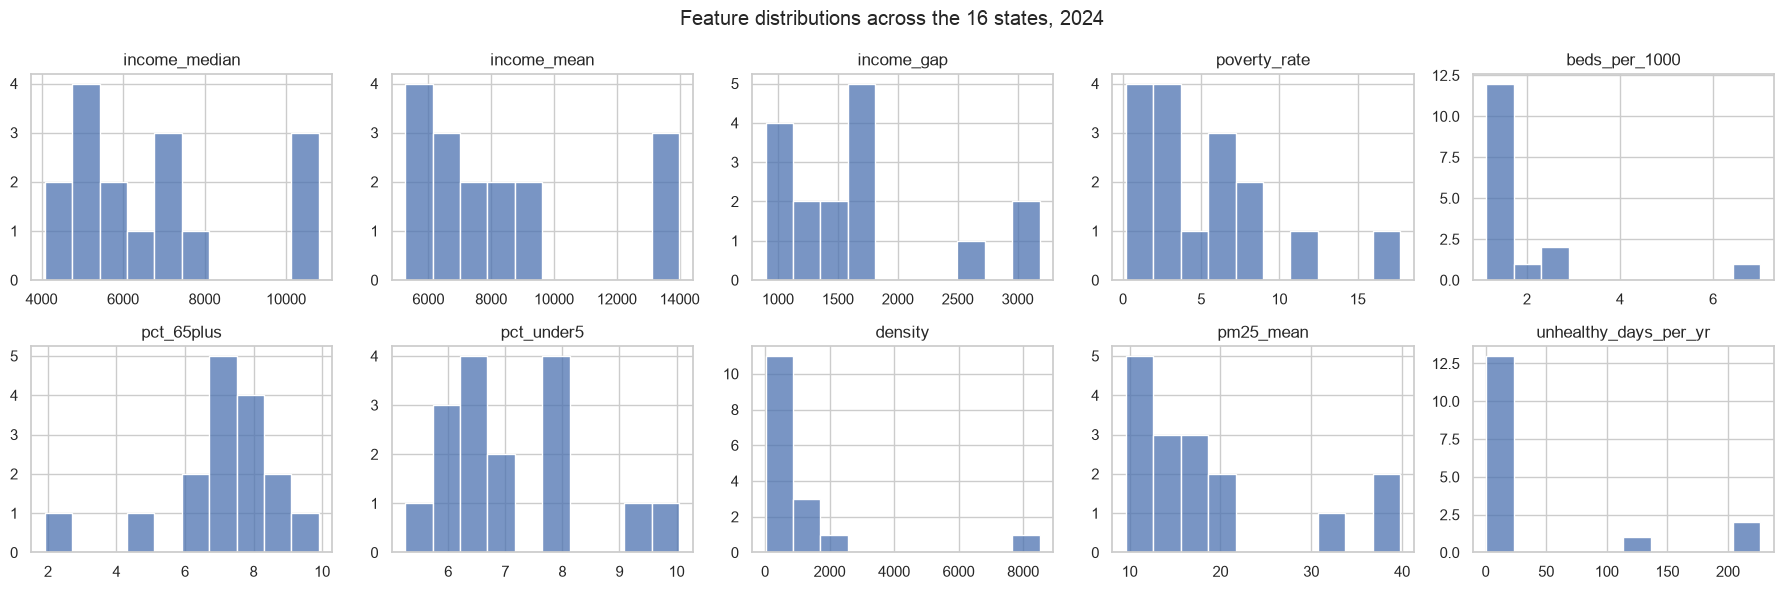

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
latest = df[df.year == YEARS[-1]]
for ax, f in zip(axes.flat, FEATURES):
    sns.histplot(latest[f], bins=10, ax=ax, color="#4c72b0")
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle(f"Feature distributions across the 16 states, {YEARS[-1]}")
fig.tight_layout()

## Median vs mean income

Mean > median everywhere (right-skewed income). A large `income_gap` means a few high earners pull the
mean up while the typical household is poorer — a signal of inequality, so it's kept as a feature.

,state,income_median,income_mean,income_gap
77,W.P. Kuala Lumpur,10802.0,13985,3183.0
79,W.P. Putrajaya,10769.0,13846,3077.0
75,Selangor,10726.0,13296,2570.0
67,Melaka,6891.0,8686,1795.0
64,Johor,7712.0,9484,1772.0
72,Pulau Pinang,7386.0,9152,1766.0


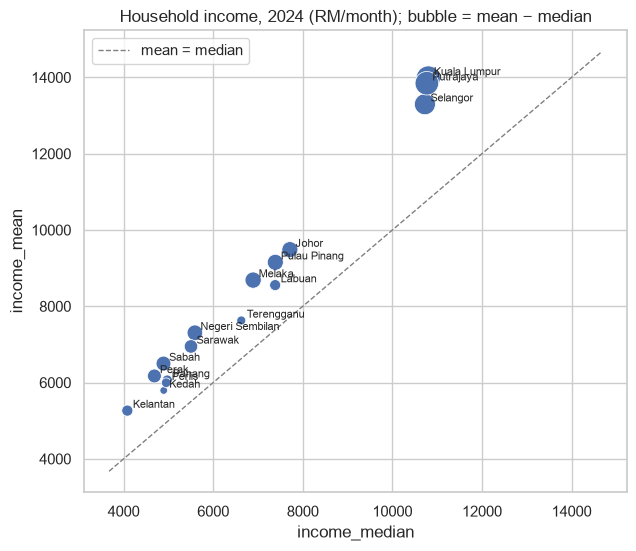

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=latest, x="income_median", y="income_mean", size="income_gap", sizes=(30, 300), legend=False, ax=ax)
lims = [latest.income_median.min() * 0.9, latest.income_mean.max() * 1.05]
ax.plot(lims, lims, ls="--", c="grey", lw=1, label="mean = median")
for _, r in latest.iterrows():
    ax.annotate(r.state.replace("W.P. ", ""), (r.income_median, r.income_mean), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_title(f"Household income, {YEARS[-1]} (RM/month); bubble = mean − median"); ax.legend()
latest[["state", "income_median", "income_mean", "income_gap"]].sort_values("income_gap", ascending=False).head(6)

## Correlations

Text(0.5, 1.0, 'Spearman correlation, 2024')

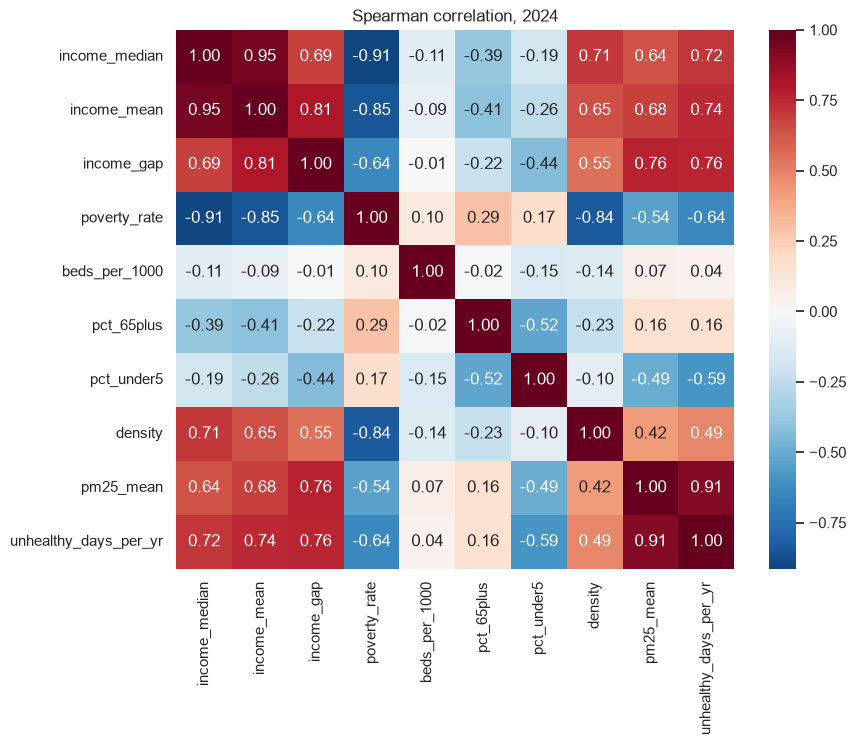

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(latest[FEATURES].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title(f"Spearman correlation, {YEARS[-1]}")

- Income median/mean are near-duplicates (ρ ≈ 0.95) and both track poverty inversely (ρ ≈ −0.9).
- Density tracks income (ρ ≈ 0.7) and poverty inversely (ρ ≈ −0.84): urban states are richer.
- **PM2.5 exposure is positively correlated with income** (unhealthy days vs median income ρ ≈ 0.72)
  because CAMS puts the highest exposure in the rich Klang Valley. So "who breathes the worst air" and
  "who is least able to cope" point at different states — the ranker labels in step 3 have to deal with this.
- beds_per_1000 is close to independent of everything else.

## Poverty line break in 2016

DOSM revised the poverty line income in 2019, so 2016 absolute poverty uses the old, much lower line
(0–3 % vs 1–20 % later). Levels aren't comparable across years — but the **ordering** of states is what
matters for a ranker.

In [13]:
wide = df.pivot(index="state", columns="year", values="poverty_rate")
print(wide.round(1))
print("\nSpearman rank correlation of poverty with 2019:")
print(wide.corr(method="spearman")[2019].round(2))

year               2016  2019  2020  2022  2024
state                                          
Johor               0.0   3.9   5.9   4.6   2.5
Kedah               0.2   8.8  12.7   9.0   8.4
Kelantan            0.4  12.4  21.2  13.2  11.5
Melaka              0.0   3.9   6.1   4.2   3.0
Negeri Sembilan     0.2   4.3   6.5   4.4   4.0
Pahang              0.2   4.3   8.8   6.3   5.9
Perak               0.2   7.3  11.4   7.5   6.9
Perlis              0.1   3.9   9.9   4.0   3.6
Pulau Pinang        0.1   1.9   3.3   2.0   1.9
Sabah               2.9  19.5  25.3  19.7  17.7
Sarawak             0.6   9.0  12.9  10.8   8.4
Selangor            0.0   1.2   1.7   1.5   0.9
Terengganu          0.4   6.1  12.0   6.2   5.8
W.P. Kuala Lumpur   0.0   0.2   0.4   1.4   1.0
W.P. Labuan         0.0   3.1   5.2   2.5   2.0
W.P. Putrajaya      0.0   0.4   0.2   0.1   0.2

Spearman rank correlation of poverty with 2019:
year
2016    0.90
2019    1.00
2020    0.98
2022    0.98
2024    0.98
Name: 2019, dtype

State ordering in 2016 still agrees strongly with later years (ρ ≈ 0.9 vs 2019), so 2016 is kept;
within-year scaling below removes the level shift.

## Scaling

Ranking groups are years, and validation is leave-one-year-out, so features must be comparable across
years despite income growth and the poverty-line break. Each feature is **z-scored within its year**
(`z_*` columns). Raw columns are kept for the UI and allocation.

In [14]:
for f in FEATURES:
    g = df.groupby("year")[f]
    std = g.transform("std").replace(0, 1)  # static PM2.5 features have std > 0 across states, guard anyway
    df[f"z_{f}"] = (df[f] - g.transform("mean")) / std

cols = (["state", "year", "population", "beds", "area_km2", "vulnerable_pop"] + FEATURES + [f"z_{f}" for f in FEATURES])
out = df[cols].round(4)
assert len(out) == 16 * len(YEARS) and out.notna().all().all()
out.to_csv(RA / "features.csv", index=False)
print(f"wrote features.csv: {out.shape}, years {YEARS}")

wrote features.csv: (80, 26), years [2016, 2019, 2020, 2022, 2024]
